# Track 1 · Step 3: leakage-safe split (train / val / test)

AI251P Capstone, Phase 1 (M1: *"leakage-safe split"*, *"class balance per split"*). Owner: Abdulmohsen Alharthi.

Input: the Step 2 outputs in `01_Data/Processed/`. Nothing in `Raw/` or the Step 2 files is changed.

What this notebook does:
1. **UAVDT occlusion / out-of-view levels**: reads the level codes from the MOTD toolkit README inside `Raw/UAVDT/UAV-benchmark-MOTD_v1.0.zip`, prints them, and rebuilds the UAVDT `crop_ok` flag from the level *names* (not from a numeric `<=` threshold).
2. **Track label audit (UAVDT)**: finds `(seq, target_id)` tracks that carry more than one category, gives each track its majority label, and writes the list (an M1 label-audit finding).
3. **Crops per track cap (UAVDT)**: consecutive 5 fps crops of one vehicle are near-identical, so each track keeps at most `TRACK_CAP[class]` crops, evenly spaced in time.
4. **Group split, seeded search**: SeaDronesSee by video (Step 2 split groups, 39), UAVDT first by sequence **prefix** (`M01`…`M14`, 14 groups). If val and test cannot each get truck and bus, UAVDT falls back to the 50 sequence groups and the limitation is written to the summary for the dataset card.
5. **Checks**: no group, video, sequence, md5 or near-duplicate pair shared by two splits.
6. **Outputs**: the split file shared with detection (Abdulelah), the classification crop list, and the class table per split.

Outputs (team naming rule `YYYY-MM-DD_Topic_vN`):
- `01_Data/Processed/Splits/…_Splits_vN.json` (video → split, sequence → split, image lists; **the file the detection track uses**)
- `01_Data/Processed/Splits/…_ClassCrops_vN.csv.gz` (one row per classification crop: dataset, split, class, source image, box)
- `01_Data/Processed/Splits/…_SplitClassTable_vN.csv` and `…_SplitClassBalance_vN.png` (for the dataset card)
- `01_Data/Processed/…_LabelAudit_UAVDTTracks_vN.csv`
- `01_Data/…_Step3Summary_vN.json`

Runtime: CPU, a few minutes. No images are decoded.

## 0. Settings

In [1]:
DRIVE_PROJECT = '/content/drive/MyDrive/AI251P_Capstone_CrossDomainAerial'
DATA_DIR  = f'{DRIVE_PROJECT}/01_Data'
RAW_DIR   = f'{DATA_DIR}/Raw'
PROC_DIR  = f'{DATA_DIR}/Processed'
SPLIT_DIR = f'{PROC_DIR}/Splits'
SEED = 42

TARGET = {'train': 0.70, 'val': 0.15, 'test': 0.15}
N_TRIES = 50_000               # random group assignments tried per dataset (then local improvement)

# Rare classes must reach every split (train, val and test) with at least this much:
SDS_RARE        = ['jetski', 'life_saving_appliances']
SDS_RARE_MIN    = 50           # crops per split
UAV_RARE        = ['truck', 'bus']
UAV_RARE_MIN    = 5            # tracks per split
MIN_GROUPS_RARE = {'SeaDronesSee': 2, 'UAVDT': 1}   # distinct groups that bring the rare class into val and into test
MAX_SHARE_GAP   = 0.08         # every class: its share in each split stays within target +- this (val/test 7-23 %, train 62-78 %)

# UAVDT crops: which occlusion / out-of-view LEVEL NAMES are good enough for a classification crop.
# The numeric codes are read from the README in section 1, never assumed.
CROP_OK_OCCLUSION   = {'no', 'small', 'medium'}    # drop 'large' occlusion (70-100 % hidden)
CROP_OK_OUT_OF_VIEW = {'no', 'small'}              # drop 'medium' out-of-view (30-50 % outside the frame)
LEVEL_CODES_MANUAL  = None    # only if the README cannot be found: {'occlusion': {1: 'no', ...}, 'out_of_view': {1: 'no', ...}}

# Crops kept per UAVDT track, evenly spaced over the track (deterministic, no sampling)
TRACK_CAP = {'car': 10, 'truck': 40, 'bus': 40}

## 1. Mount Drive, find the Step 2 outputs

In [2]:
from google.colab import drive
drive.mount('/content/drive')

import os, re, json, time, zipfile
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
os.makedirs(SPLIT_DIR, exist_ok=True)

TODAY = time.strftime('%Y-%m-%d')
_done = [int(m.group(1)) for f in os.listdir(DATA_DIR) if (m := re.match(rf'{TODAY}_Step3Summary_v(\d+)\.json$', f))]
VERSION = max(_done, default=0) + 1
def out_name(topic, ext): return f'{TODAY}_{topic}_v{VERSION}.{ext}'

def latest(folder, topic, ext):
    """Newest file named YYYY-MM-DD_<topic>_vN.<ext> (latest date, then highest N)."""
    hits = []
    for f in os.listdir(folder):
        m = re.match(rf'(\d{{4}}-\d{{2}}-\d{{2}})_{topic}_v(\d+)\.{re.escape(ext)}$', f)
        if m: hits.append((m.group(1), int(m.group(2)), f))
    assert hits, f'no {topic} file in {folder}: run Step 2 first'
    return f'{folder}/{max(hits)[2]}'

IN = {'sds_clean':  latest(f'{PROC_DIR}/SeaDronesSee', 'SDSClean', 'json'),
      'sds_pairs':  latest(f'{PROC_DIR}/SeaDronesSee', 'SDSNearDupVideoPairs', 'csv'),
      'uav_boxes':  latest(f'{PROC_DIR}/UAVDT', 'UAVDTBoxes', 'csv.gz'),
      'uav_frames': latest(f'{PROC_DIR}/UAVDT', 'UAVDTFrames', 'csv'),
      'uav_pairs':  latest(f'{PROC_DIR}/UAVDT', 'UAVDTNearDupSeqPairs', 'csv'),
      'step2':      latest(DATA_DIR, 'Step2Summary', 'json')}
for k, v in IN.items(): print(f'{k:11s}', Path(v).name)
STEP2 = json.load(open(IN['step2']))
MIN_CROP_SIDE = STEP2['thresholds']['MIN_CROP_SIDE']
print('outputs of this run use version', VERSION)
SUMMARY = {'seed': SEED, 'created': time.strftime('%Y-%m-%d %H:%M'), 'version': VERSION,
           'inputs': {k: Path(v).name for k, v in IN.items()},
           'settings': {'TARGET': TARGET, 'N_TRIES': N_TRIES, 'SDS_RARE': SDS_RARE, 'SDS_RARE_MIN': SDS_RARE_MIN,
                        'UAV_RARE': UAV_RARE, 'UAV_RARE_MIN': UAV_RARE_MIN, 'MIN_GROUPS_RARE': MIN_GROUPS_RARE,
                        'MAX_SHARE_GAP': MAX_SHARE_GAP,
                        'CROP_OK_OCCLUSION': sorted(CROP_OK_OCCLUSION), 'CROP_OK_OUT_OF_VIEW': sorted(CROP_OK_OUT_OF_VIEW),
                        'TRACK_CAP': TRACK_CAP, 'MIN_CROP_SIDE': MIN_CROP_SIDE}}

Mounted at /content/drive
sds_clean   2026-10-18_SDSClean_v1.json
sds_pairs   2026-10-18_SDSNearDupVideoPairs_v1.csv
uav_boxes   2026-10-18_UAVDTBoxes_v1.csv.gz
uav_frames  2026-10-18_UAVDTFrames_v1.csv
uav_pairs   2026-10-18_UAVDTNearDupSeqPairs_v1.csv
step2       2026-10-18_Step2Summary_v1.json
outputs of this run use version 1


## 2. UAVDT: occlusion and out-of-view codes from the toolkit README

Step 2 used `occlusion <= 3` and `out_of_view <= 2`. That is only right if the codes grow with severity. This cell prints the README text about both fields and parses the codes (`'no-occ'=1`, …). **Read the printed lines and check them.** If the README orders the levels differently from 1 → 4 = none → large, the Step 2 `crop_ok` flag was wrong and the rebuilt flag below replaces it.

In [3]:
def readme_texts():
    out = []
    for z in sorted(Path(f'{RAW_DIR}/UAVDT').glob('*.zip')):
        with zipfile.ZipFile(z) as Z:
            for n in Z.namelist():
                b = Path(n).name.lower()
                if 'readme' in b or (b.endswith('.txt') and not re.match(r'm\d{4}_', b)):
                    out.append((f'{z.name}:{n}', Z.read(n).decode('utf-8', 'replace')))
    for p in Path('/content/data/uavdt').rglob('*') if Path('/content/data/uavdt').exists() else []:
        if p.is_file() and 'readme' in p.name.lower(): out.append((str(p), p.read_text(errors='replace')))
    return out

texts = readme_texts()
print('README-like files found:', [n for n, _ in texts])
CODES = {'occlusion': {}, 'out_of_view': {}}
for name, t in texts:
    lines = t.splitlines()
    for i, l in enumerate(lines):
        if re.search(r'occ|out-of-view|out_of_view|outside', l, re.I):
            print(f'{name} | {l.strip()}')
    for lvl, kind, num in re.findall(r"['\"]?(no|small|medium|large)-(occ|out)['\"]?\s*=\s*(\d)", t, re.I):
        CODES['occlusion' if kind.lower() == 'occ' else 'out_of_view'][int(num)] = lvl.lower()
if not CODES['occlusion'] or not CODES['out_of_view']:
    assert LEVEL_CODES_MANUAL, ('Level codes not found in any README. Open the MOTD README, then set LEVEL_CODES_MANUAL '
                                'in section 0, e.g. {"occlusion": {1: "no", 2: "large", ...}, "out_of_view": {...}}')
    CODES = {k: {int(c): v for c, v in d.items()} for k, d in LEVEL_CODES_MANUAL.items()}
print('\nparsed codes:', CODES)
SUMMARY['uavdt_level_codes'] = {'source': [n for n, _ in texts] or 'LEVEL_CODES_MANUAL', **CODES}

README-like files found: ['M_attr.zip:M_attr/readme.txt', 'M_attr.zip:M_attr/test/M0701 _attr.txt', 'UAV-benchmark-MOTD_v1.0.zip:UAV-benchmark-MOTD_v1.0/README.md', 'UAV-benchmark-MOTD_v1.0.zip:UAV-benchmark-MOTD_v1.0/RES_DET/det_FRCNN/M0203.txt', 'UAV-benchmark-MOTD_v1.0.zip:UAV-benchmark-MOTD_v1.0/RES_DET/det_FRCNN/M0205.txt', 'UAV-benchmark-MOTD_v1.0.zip:UAV-benchmark-MOTD_v1.0/RES_DET/det_FRCNN/M0208.txt', 'UAV-benchmark-MOTD_v1.0.zip:UAV-benchmark-MOTD_v1.0/RES_DET/det_FRCNN/M0209.txt', 'UAV-benchmark-MOTD_v1.0.zip:UAV-benchmark-MOTD_v1.0/RES_DET/det_FRCNN/M0403.txt', 'UAV-benchmark-MOTD_v1.0.zip:UAV-benchmark-MOTD_v1.0/RES_DET/det_FRCNN/M0601.txt', 'UAV-benchmark-MOTD_v1.0.zip:UAV-benchmark-MOTD_v1.0/RES_DET/det_FRCNN/M0602.txt', 'UAV-benchmark-MOTD_v1.0.zip:UAV-benchmark-MOTD_v1.0/RES_DET/det_FRCNN/M0606.txt', 'UAV-benchmark-MOTD_v1.0.zip:UAV-benchmark-MOTD_v1.0/RES_DET/det_FRCNN/M0701.txt', 'UAV-benchmark-MOTD_v1.0.zip:UAV-benchmark-MOTD_v1.0/RES_DET/det_FRCNN/M0801.txt', 'UAV-

## 3. UAVDT: rebuild `crop_ok` from level names, compare with Step 2

In [5]:
# README typo: 'lagre-occ'=2 means 'large-occ'
occ = CODES['occlusion']
print('before:', occ)
ref = occ.get(3) or occ.get(4)
occ[2] = ref.replace('medium', 'large').replace('small', 'large')
print('after:', occ)

ub = pd.read_csv(IN['uav_boxes'])
ub['occ_level'] = ub.occlusion.map(CODES['occlusion'])
ub['oov_level'] = ub.out_of_view.map(CODES['out_of_view'])
assert ub.occ_level.notna().all() and ub.oov_level.notna().all(), \
    f"codes in the GT not covered by the README: occ {sorted(ub.occlusion[ub.occ_level.isna()].unique())}, oov {sorted(ub.out_of_view[ub.oov_level.isna()].unique())}"
print('boxes per occlusion level (5 fps):');   display(pd.crosstab(ub.occ_level, ub.category, margins=True))
print('boxes per out-of-view level (5 fps):'); display(pd.crosstab(ub.oov_level, ub.category, margins=True))

ub['crop_ok_step2'] = ub.crop_ok.astype(bool)
ub['crop_ok'] = ((ub[['w', 'h']].min(1) >= MIN_CROP_SIDE) & ~ub.truncated.astype(bool) & ~ub.in_ignore.astype(bool)
                 & ub.occ_level.isin(CROP_OK_OCCLUSION) & ub.oov_level.isin(CROP_OK_OUT_OF_VIEW))
cmp = ub.groupby('category').agg(boxes=('crop_ok', 'size'), crop_ok_step2=('crop_ok_step2', 'sum'), crop_ok_step3=('crop_ok', 'sum'))
cmp['changed_boxes'] = ub.groupby('category').apply(lambda g: int((g.crop_ok != g.crop_ok_step2).sum()))
display(cmp)
SUMMARY['uavdt_crop_ok'] = cmp.to_dict(orient='index')

before: {1: 'no', 3: 'medium', 4: 'small'}
after: {1: 'no', 3: 'medium', 4: 'small', 2: 'large'}
boxes per occlusion level (5 fps):


category,bus,car,truck,All
occ_level,,,,
large,29,1492,40,1561
medium,65,1546,59,1670
no,2498,113426,3617,119541
small,420,9779,489,10688
All,3012,126243,4205,133460


boxes per out-of-view level (5 fps):


category,bus,car,truck,All
oov_level,,,,
medium,154,5804,194,6152
no,2632,114802,3732,121166
small,226,5637,279,6142
All,3012,126243,4205,133460


/tmp/ipykernel_1022/145988228.py:20: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  cmp['changed_boxes'] = ub.groupby('category').apply(lambda g: int((g.crop_ok != g.crop_ok_step2).sum()))


,boxes,crop_ok_step2,crop_ok_step3,changed_boxes
category,,,,
bus,3012,2359,2805,784
car,126243,110783,118482,21701
truck,4205,3442,3965,933


## 4. UAVDT: track label audit (majority label per track)

A track is one `(seq, target_id)`. Step 2 counted truck 96 / bus 56 tracks over all boxes but 75 / 41 among crop tracks. The difference has two possible causes, separated here: tracks whose boxes carry **more than one category**, and tracks with **no usable crop**. A mixed track gets the label of most of its boxes (tie: the label of most of its `crop_ok` boxes, then the label of its first box); its crops are relabelled for classification. The detection labels in Step 2 are not changed; the list goes to the label audit (Step 4) and to Abdulelah.

In [6]:
ub['track'] = ub.seq + '_' + ub.target_id.astype(str)
per = ub.groupby(['track', 'category']).agg(n=('frame', 'size'), n_ok=('crop_ok', 'sum'), first=('frame', 'min')).reset_index()
per = per.sort_values(['track', 'n', 'n_ok', 'first'], ascending=[True, False, False, True])
major = per.drop_duplicates('track').set_index('track').category.rename('track_label')
ncat = per.groupby('track').category.nunique()
mixed = ncat[ncat > 1].index
ties = per[per.track.isin(mixed)].groupby('track').n.apply(lambda s: (s == s.max()).sum() > 1)

audit = (per[per.track.isin(mixed)].pivot_table(index='track', columns='category', values='n', fill_value=0)
         .join(major).join(ties.rename('tie')))
audit['boxes_relabelled'] = audit.drop(columns=['track_label', 'tie']).sum(1) - audit.apply(lambda r: r[r.track_label], axis=1)
audit.to_csv(f'{PROC_DIR}/{out_name("LabelAudit_UAVDTTracks", "csv")}')
ub = ub.join(major, on='track')

tracks_any = ub.groupby('category').track.nunique()                     # Step 2 cell 14 style
has_ok = ub.groupby('track').crop_ok.any()
tr = ub.drop_duplicates('track').set_index('track').track_label
explain = pd.DataFrame({'tracks_by_any_box_label': tracks_any,
                        'tracks_by_majority_label': tr.value_counts(),
                        'with_ge1_crop': tr[has_ok].value_counts(),
                        'mixed_tracks_with_this_label_somewhere': per[per.track.isin(mixed)].category.value_counts()}).fillna(0).astype(int)
display(explain)
print(f'tracks: {len(tr)} | with more than one category: {len(mixed)} ({len(mixed)/len(tr):.2%}) | ties: {int(ties.sum())} | '
      f'boxes relabelled: {int(audit.boxes_relabelled.sum())} of {len(ub)}')
display(audit.sort_values('boxes_relabelled', ascending=False).head(15))
SUMMARY['uavdt_track_audit'] = {'tracks': int(len(tr)), 'mixed_label_tracks': int(len(mixed)), 'ties': int(ties.sum()),
                                'boxes_relabelled': int(audit.boxes_relabelled.sum()), 'boxes_total': int(len(ub)),
                                'mixed_pairs': per[per.track.isin(mixed)].groupby('track').category
                                               .apply(lambda s: '+'.join(sorted(s))).value_counts().to_dict(),
                                'explain_track_counts': explain.to_dict(orient='index')}

,tracks_by_any_box_label,tracks_by_majority_label,with_ge1_crop,mixed_tracks_with_this_label_somewhere
bus,56,53,50,11
car,2523,2499,2429,32
truck,96,90,87,22


tracks: 2642 | with more than one category: 32 (1.21%) | ties: 2 | boxes relabelled: 516 of 133460


,bus,car,truck,track_label,tie,boxes_relabelled
track,,,,,,
M0701_163,68.0,82.0,0.0,car,False,68.0
M1301_93,0.0,68.0,86.0,truck,False,68.0
M0702_44,80.0,50.0,0.0,bus,False,50.0
M0701_31,100.0,23.0,16.0,bus,False,39.0
M0603_17,0.0,35.0,35.0,truck,True,35.0
M0605_49,0.0,30.0,35.0,truck,False,30.0
M1201_9,0.0,25.0,54.0,truck,False,25.0
M1001_98,24.0,20.0,0.0,bus,False,20.0
M0602_43,0.0,18.0,30.0,truck,False,18.0


## 5. UAVDT: cap crops per track

`TRACK_CAP` crops per track, evenly spaced from the first to the last usable frame. Truck and bus keep more frames per track than car because they are rare; class imbalance that remains is handled in training (Step 5: class weights or a balanced sampler), not by dropping data.

In [7]:
def even_pick(g, cap):
    g = g.sort_values('frame')
    if len(g) <= cap: return g
    return g.iloc[np.unique(np.linspace(0, len(g) - 1, cap).round().astype(int))]

ok = ub[ub.crop_ok]
uav_crops = pd.concat([even_pick(g, TRACK_CAP[g.track_label.iloc[0]]) for _, g in ok.groupby('track')], ignore_index=True)
cap_tab = pd.DataFrame({'crops_before_cap': ok.track_label.value_counts(), 'crops_after_cap': uav_crops.track_label.value_counts(),
                        'tracks': uav_crops.drop_duplicates('track').track_label.value_counts(),
                        'cap_per_track': pd.Series(TRACK_CAP)})
display(cap_tab)
SUMMARY['uavdt_track_cap'] = cap_tab.fillna(0).astype(int).to_dict(orient='index')

,crops_before_cap,crops_after_cap,tracks,cap_per_track
car,118225,22740,2429,10
truck,4163,2550,87,40
bus,2864,1620,50,40


## 6. The search

Each group goes to one split. `N_TRIES` random assignments (seeded) are scored, the best is kept, then moving one group or swapping two groups is tried until nothing improves it. Constraint shortfalls count as a large penalty, so the result either meets every constraint or the notebook says it cannot.

- **Score**: for every class, how far its share in train / val / test is from 70 / 15 / 15 (sum of absolute gaps), averaged over classes with equal weight, so rare classes count as much as swimmer or car.
- **Constraints**: every rare class reaches train, val and test with at least the minimum, from at least `MIN_GROUPS_RARE` groups in val and in test; and every class keeps its share in each split within `MAX_SHARE_GAP` of the target.

In [8]:
SPLITS = list(TARGET); T = np.array([TARGET[s] for s in SPLITS])

def split_search(M, rare, rare_min, min_groups, n_tries=N_TRIES, seed=SEED):
    """M: DataFrame groups x classes (counts). Returns (assignment Series, info dict) or (None, info) if no assignment
    meets the constraints. Constraint shortfalls are added to the score as a penalty, so the local improvement can
    also walk from a near-miss to a valid assignment."""
    X = M.to_numpy(float); G, K = X.shape; tot = X.sum(0); has = (X > 0).astype(float)
    ri = [M.columns.get_loc(c) for c in rare]
    rng = np.random.default_rng(seed)

    def evaluate(A):                         # A: tries x groups, values 0/1/2 -> (score, penalised score, valid)
        S = np.stack([(A == k) @ X for k in range(3)], 1)          # tries x 3 x K
        Hg = np.stack([(A == k) @ has for k in range(3)], 1)
        gap = np.abs(S / tot - T[None, :, None])
        score = gap.sum(1).mean(1)
        short = (np.clip(rare_min - S[:, :, ri], 0, None) / rare_min).sum((1, 2)) \
              + np.clip(min_groups - Hg[:, 1:, ri], 0, None).sum((1, 2)) \
              + np.clip(gap - MAX_SHARE_GAP, 0, None).sum((1, 2)) * 10
        return score, score + 10 * short, short == 0

    A = rng.choice(3, size=(n_tries, G), p=T)
    score, obj, ok = evaluate(A)
    info = {'groups': G, 'tries': n_tries, 'valid_random_tries': int(ok.sum())}
    best = A[np.argmin(obj)].copy(); bo = obj.min()
    I, Jx = np.triu_indices(G, 1); r = np.arange(len(I))
    improved = True
    while improved:                          # local improvement: move one group, or swap two groups
        improved = False
        mv = np.repeat(best[None], G * 3, 0)
        for g in range(G): mv[g * 3:(g + 1) * 3, g] = [0, 1, 2]
        sw = np.repeat(best[None], len(I), 0); sw[r, I], sw[r, Jx] = best[Jx], best[I]
        cand = np.vstack([mv, sw])
        _, o, _ = evaluate(cand); j = np.argmin(o)
        if o[j] < bo - 1e-12: best, bo, improved = cand[j].copy(), o[j], True
    s, _, v = evaluate(best[None])
    info.update(score=float(s[0]), valid=bool(v[0]))
    if not v[0]: return None, info
    return pd.Series([SPLITS[k] for k in best], index=M.index, name='split'), info

def merge_by_pairs(key_of, pairs):
    """Groups joined by ANY near-identical pair (also pairs below Step 2's MIN_PAIRS_TO_LINK) are searched as one unit,
    so a near-duplicate pair can never end up across two splits. key_of: item (video/sequence) -> group key."""
    parent = {k: k for k in set(key_of.values())}
    def find(x):
        while parent[x] != x: parent[x] = parent[parent[x]]; x = parent[x]
        return x
    for p in pairs.itertuples():
        if p.a in key_of and p.b in key_of: parent[find(key_of[p.a])] = find(key_of[p.b])
    unit = {k: find(k) for k in parent}
    joined = {u: sorted(k for k in parent if unit[k] == u) for u in set(unit.values())}
    joined = {'+'.join(v): v for v in joined.values() if len(v) > 1}
    return {k: '+'.join(sorted(kk for kk in parent if unit[kk] == unit[k])) for k in parent}, joined

def share_table(M, assign):
    t = M.groupby(assign).sum().T[SPLITS]
    return t.join((t.div(t.sum(1), axis=0) * 100).round(1).add_suffix('_%'))

## 7. SeaDronesSee: split by video group

In [9]:
J = json.load(open(IN['sds_clean']))
CATS = {c['id']: c['name'] for c in J['categories']}
sds_img = pd.DataFrame(J['images']).rename(columns={'id': 'image_id'})
sds_ann = pd.DataFrame(J['annotations']).rename(columns={'id': 'ann_id'})
sds_ann['category'] = sds_ann.category_id.map(CATS)
sds_ann = sds_ann.merge(sds_img[['image_id', 'file_name', 'video', 'split_group']], on='image_id')
unit_of, joined = merge_by_pairs(sds_img.drop_duplicates('video').set_index('video').split_group.to_dict(), pd.read_csv(IN['sds_pairs']))
print('groups joined because of near-identical pairs below the Step 2 link threshold:', joined or 'none')
sds_img['unit'] = sds_img.split_group.map(unit_of); sds_ann['unit'] = sds_ann.split_group.map(unit_of)
sds_crops = sds_ann[sds_ann.crop_ok.astype(bool) & (sds_ann.iscrowd == 0)].copy()
M_sds = sds_crops.pivot_table(index='unit', columns='category', values='ann_id', aggfunc='size', fill_value=0)
assert set(SDS_RARE) <= set(M_sds.columns), f'rare class names not found: {SDS_RARE} vs {list(M_sds.columns)}'
print(f'{len(M_sds)} groups, {len(sds_crops)} crops'); display(M_sds.sum())

sds_assign, sds_info = split_search(M_sds, SDS_RARE, SDS_RARE_MIN, MIN_GROUPS_RARE['SeaDronesSee'])
assert sds_assign is not None, f'no SeaDronesSee assignment meets the constraints: {sds_info}. Lower SDS_RARE_MIN or MIN_GROUPS_RARE.'
print(sds_info); display(share_table(M_sds, sds_assign))
print('groups per split:', sds_assign.value_counts().to_dict())

groups joined because of near-identical pairs below the Step 2 link threshold: none
39 groups, 67366 crops


,0
category,
boat,15232
buoy,4945
jetski,2650
life_saving_appliances,1253
swimmer,43286


{'groups': 39, 'tries': 50000, 'valid_random_tries': 1, 'score': 0.06704515837977414, 'valid': True}


split,train,val,test,train_%,val_%,test_%
category,,,,,,
boat,9707,2319,3206,63.7,15.2,21.0
buoy,3476,659,810,70.3,13.3,16.4
jetski,1793,443,414,67.7,16.7,15.6
life_saving_appliances,856,213,184,68.3,17.0,14.7
swimmer,32238,6093,4955,74.5,14.1,11.4


groups per split: {'train': 30, 'val': 5, 'test': 4}


## 8. UAVDT: split by sequence prefix, fall back to sequences

Counted in **tracks** per class (majority label, tracks with at least one usable crop), because crops of one track are near-identical.

In [10]:
uav_pairs = pd.read_csv(IN['uav_pairs'])
all_seqs = sorted(pd.read_csv(IN['uav_frames'], usecols=['seq']).seq.unique())
def units(level):                      # sequence -> search unit, for 'prefix' or 'sequence' grouping
    key = {s: s[:3] if level == 'prefix' else s for s in all_seqs}
    u, j = merge_by_pairs(key, uav_pairs)
    return {s: u[key[s]] for s in all_seqs}, j
def uav_matrix(level):
    global UNIT, uav_joined
    UNIT, uav_joined = units(level); print('units joined because of near-identical pairs:', uav_joined or 'none')
    uav_crops['unit'] = uav_crops.seq.map(UNIT)
    col = 'unit'
    return uav_crops.drop_duplicates('track').pivot_table(index=col, columns='track_label', values='track',
                                                          aggfunc='size', fill_value=0)
UAV_GROUPING, UAV_LIMITATION = 'prefix', None
M_uav = uav_matrix('prefix')
print('prefix groups:', len(M_uav)); display(M_uav)
uav_assign, uav_info = split_search(M_uav, UAV_RARE, UAV_RARE_MIN, MIN_GROUPS_RARE['UAVDT'])
uav_info['grouping'] = 'prefix'
if uav_assign is None:
    print(f'No prefix assignment gives val and test each >= {UAV_RARE_MIN} tracks of {UAV_RARE} with every class share within '
          f'+-{MAX_SHARE_GAP:.0%} of 70/15/15 -> falling back to sequences', uav_info)
    UAV_GROUPING = 'sequence'
    UAV_LIMITATION = (f'UAVDT was split by sequence, not by sequence prefix (M01..M14): with {len(M_uav)} prefix groups no '
                      f'assignment gave val and test each >= {UAV_RARE_MIN} truck and bus tracks with every class share within '
                      f'+-{MAX_SHARE_GAP:.0%} of 70/15/15. Sequences that share a '
                      'prefix may come from the same flight or site, so val/test scores on UAVDT may be optimistic.')
    prefix_info = uav_info
    M_uav = uav_matrix('sequence')
    uav_assign, uav_info = split_search(M_uav, UAV_RARE, UAV_RARE_MIN, MIN_GROUPS_RARE['UAVDT'])
    uav_info.update(grouping='sequence', prefix_attempt=prefix_info)
    assert uav_assign is not None, f'no UAVDT assignment even by sequence: {uav_info}'
print(uav_info); display(share_table(M_uav, uav_assign))
# every sequence gets a split (detection uses all of them); a sequence with no usable crop follows its unit, else train
seq_split = pd.Series({q: uav_assign.get(UNIT[q], 'train') for q in all_seqs})
print('sequences per split:', seq_split.value_counts().to_dict())

units joined because of near-identical pairs: none
prefix groups: 14


track_label,bus,car,truck
unit,,,
M01,1,18,1
M02,3,277,12
M03,0,17,1
M04,0,192,4
M05,1,18,0
M06,12,375,14
M07,12,405,20
M08,1,87,2
M09,0,33,0


No prefix assignment gives val and test each >= 5 tracks of ['truck', 'bus'] with every class share within +-8% of 70/15/15 -> falling back to sequences {'groups': 14, 'tries': 50000, 'valid_random_tries': 0, 'score': 0.07175341381045437, 'valid': False, 'grouping': 'prefix'}
units joined because of near-identical pairs: none
{'groups': 50, 'tries': 50000, 'valid_random_tries': 2862, 'score': 0.007611350081786335, 'valid': True, 'grouping': 'sequence', 'prefix_attempt': {'groups': 14, 'tries': 50000, 'valid_random_tries': 0, 'score': 0.07175341381045437, 'valid': False, 'grouping': 'prefix'}}


split,train,val,test,train_%,val_%,test_%
track_label,,,,,,
bus,35,8,7,70.0,16.0,14.0
car,1700,365,364,70.0,15.0,15.0
truck,61,13,13,70.1,14.9,14.9


sequences per split: {'train': 34, 'test': 9, 'val': 7}


## 9. Checks: nothing shared between splits

In [11]:
sds_img['split'] = sds_img.unit.map(sds_assign).fillna('train')   # groups with no crop go to train
uf = pd.read_csv(IN['uav_frames']); uf['split'] = uf.seq.map(seq_split)
CHECKS = {}
CHECKS['sds_video_in_two_splits'] = int((sds_img.groupby('video').split.nunique() > 1).sum())
CHECKS['sds_group_in_two_splits'] = int((sds_img.groupby('split_group').split.nunique() > 1).sum())
CHECKS['uav_seq_in_two_splits'] = int((uf.groupby('seq').split.nunique() > 1).sum())
if UAV_GROUPING == 'prefix':
    CHECKS['uav_prefix_in_two_splits'] = int((uf.assign(p=uf.seq.str[:3]).groupby('p').split.nunique() > 1).sum())
md5 = pd.concat([sds_img[['md5', 'split']], uf[['md5', 'split']]]).dropna()
CHECKS['md5_in_two_splits'] = int((md5.groupby('md5').split.nunique() > 1).sum())
vs = sds_img.drop_duplicates('video').set_index('video').split
p = pd.read_csv(IN['sds_pairs'])
CHECKS['sds_neardup_pairs_across_splits'] = int(p[p.a.map(vs) != p.b.map(vs)].pairs.sum()) if len(p) else 0
p = pd.read_csv(IN['uav_pairs'])
CHECKS['uav_neardup_pairs_across_splits'] = int(p[p.a.map(seq_split) != p.b.map(seq_split)].pairs.sum()) if len(p) else 0
for k, v in CHECKS.items(): print(f'{k:35s} {v}  {"OK" if v == 0 else "PROBLEM"}')
SUMMARY['checks'] = CHECKS
assert all(v == 0 for v in CHECKS.values()), 'leakage check failed: see the lines marked PROBLEM'

sds_video_in_two_splits             0  OK
sds_group_in_two_splits             0  OK
uav_seq_in_two_splits               0  OK
md5_in_two_splits                   0  OK
sds_neardup_pairs_across_splits     0  OK
uav_neardup_pairs_across_splits     0  OK


## 10. Class table per split (for the dataset card) and outputs

split,train,val,test,train_%,val_%,test_%,train_tracks,val_tracks,test_tracks,train_groups,val_groups,test_groups
category,,,,,,,,,,,,
swimmer,32238.0,6093.0,4955.0,74.5,14.1,11.4,0.0,0.0,0.0,26.0,5.0,4.0
boat,9707.0,2319.0,3206.0,63.7,15.2,21.0,0.0,0.0,0.0,29.0,4.0,4.0
jetski,1793.0,443.0,414.0,67.7,16.7,15.6,0.0,0.0,0.0,13.0,2.0,2.0
life_saving_appliances,856.0,213.0,184.0,68.3,17.0,14.7,0.0,0.0,0.0,5.0,2.0,2.0
buoy,3476.0,659.0,810.0,70.3,13.3,16.4,0.0,0.0,0.0,14.0,2.0,2.0
car,15969.0,3383.0,3388.0,70.2,14.9,14.9,1700.0,365.0,364.0,34.0,7.0,9.0
truck,1807.0,398.0,345.0,70.9,15.6,13.5,61.0,13.0,13.0,22.0,5.0,5.0
bus,1079.0,292.0,249.0,66.6,18.0,15.4,35.0,8.0,7.0,14.0,5.0,4.0
total,66925.0,13800.0,13551.0,71.0,14.6,14.4,1796.0,386.0,384.0,157.0,32.0,32.0


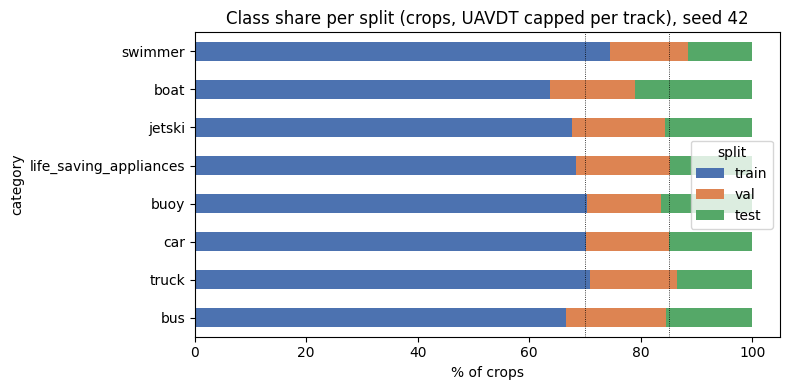

In [12]:
sds_crops['split'] = sds_crops.unit.map(sds_assign)
uav_crops['split'] = uav_crops.seq.map(seq_split)
crops = pd.concat([
    pd.DataFrame({'dataset': 'SeaDronesSee', 'split': sds_crops.split, 'category': sds_crops.category,
                  'image': sds_crops.file_name, 'x': sds_crops.bbox.str[0], 'y': sds_crops.bbox.str[1],
                  'w': sds_crops.bbox.str[2], 'h': sds_crops.bbox.str[3], 'group': sds_crops.split_group,
                  'source': sds_crops.video, 'track': '', 'ann_id': sds_crops.ann_id.astype(str), 'label_changed': False}),
    pd.DataFrame({'dataset': 'UAVDT', 'split': uav_crops.split, 'category': uav_crops.track_label,
                  'image': uav_crops.seq + '/img' + uav_crops.frame.map('{:06d}'.format) + '.jpg',
                  'x': uav_crops.x, 'y': uav_crops.y, 'w': uav_crops.w, 'h': uav_crops.h,
                  'group': uav_crops.unit,
                  'source': uav_crops.seq, 'track': uav_crops.track, 'ann_id': '',
                  'label_changed': uav_crops.category != uav_crops.track_label})], ignore_index=True)
crops.to_csv(f'{SPLIT_DIR}/{out_name("ClassCrops", "csv.gz")}', index=False)

ORDER = ['swimmer', 'boat', 'jetski', 'life_saving_appliances', 'buoy', 'car', 'truck', 'bus']
tab = crops.pivot_table(index='category', columns='split', values='image', aggfunc='size', fill_value=0)[SPLITS].reindex(ORDER)
trk = crops[crops.dataset == 'UAVDT'].drop_duplicates('track').pivot_table(index='category', columns='split', values='track',
                                                                         aggfunc='size', fill_value=0)[SPLITS].add_suffix('_tracks')
grp = crops.drop_duplicates(['category', 'group']).pivot_table(index='category', columns='split', values='group',
                                                               aggfunc='size', fill_value=0)[SPLITS].add_suffix('_groups')
table = tab.join((tab.div(tab.sum(1), axis=0) * 100).round(1).add_suffix('_%')).join(trk).join(grp).fillna(0)
table.loc['total'] = table.sum(numeric_only=True); table.loc['total', [f'{s}_%' for s in SPLITS]] = \
    (tab.sum() / tab.values.sum() * 100).round(1).to_numpy()
table.to_csv(f'{SPLIT_DIR}/{out_name("SplitClassTable", "csv")}')
display(table)

ax = (tab.div(tab.sum(1), axis=0) * 100).plot.barh(stacked=True, figsize=(8, 4), color=['#4C72B0', '#DD8452', '#55A868'])
for x in (70, 85): ax.axvline(x, color='k', lw=.6, ls=':')
ax.invert_yaxis(); ax.set_xlabel('% of crops'); ax.set_title(f'Class share per split (crops, UAVDT capped per track), seed {SEED}')
plt.tight_layout(); plt.savefig(f'{SPLIT_DIR}/{out_name("SplitClassBalance", "png")}', dpi=150); plt.show()

In [13]:
splits = {
    'info': {'created': SUMMARY['created'], 'version': VERSION, 'seed': SEED, 'target': TARGET,
             'note': 'Group split, Track 1 Step 3. Use video_to_split (SeaDronesSee) and seq_to_split (UAVDT) for '
                     'detection and segmentation too, so no flight or sequence is in two splits across tracks.',
             'inputs': SUMMARY['inputs']},
    'seadronessee': {'grouping': 'video (Step 2 split groups)',
                     'group_to_split': sds_img.drop_duplicates('split_group').set_index('split_group').split.to_dict(),
                     'joined_groups': joined,
                     'video_to_split': vs.to_dict(),
                     'images': {s: sorted(sds_img.loc[sds_img.split == s, 'file_name']) for s in SPLITS}},
    'uavdt': {'grouping': UAV_GROUPING, 'limitation': UAV_LIMITATION,
              'group_to_split': uav_assign.to_dict(), 'joined_groups': uav_joined, 'seq_to_split': seq_split.to_dict(),
              'frame_step': 6, 'frames': 'all 5 fps frames of a sequence belong to its split'}}
json.dump(splits, open(f'{SPLIT_DIR}/{out_name("Splits", "json")}', 'w'), indent=1)

def jsonable(o):
    if isinstance(o, dict): return {str(k): jsonable(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)): return [jsonable(v) for v in o]
    if isinstance(o, (np.integer,)): return int(o)
    if isinstance(o, (np.floating, float)): return None if o != o else float(o)
    if isinstance(o, np.bool_): return bool(o)
    return o
SUMMARY.update({'sds_search': sds_info, 'sds_joined_groups': joined, 'uav_joined_groups': uav_joined, 'uav_search': uav_info, 'uav_grouping': UAV_GROUPING, 'uav_limitation': UAV_LIMITATION,
                'groups_per_split': {'SeaDronesSee': sds_assign.value_counts().to_dict(), 'UAVDT': uav_assign.value_counts().to_dict()},
                'sequences_per_split': seq_split.value_counts().to_dict(),
                'images_per_split_sds': sds_img.split.value_counts().to_dict(),
                'frames_5fps_per_split_uav': uf[uf.keep_5fps.astype(bool)].split.value_counts().to_dict(),
                'class_table': table.to_dict(orient='index'),
                'outputs': [out_name(t, e) for t, e in (('Splits', 'json'), ('ClassCrops', 'csv.gz'), ('SplitClassTable', 'csv'),
                                                         ('SplitClassBalance', 'png'), ('LabelAudit_UAVDTTracks', 'csv'))]})
out = f'{DATA_DIR}/{out_name("Step3Summary", "json")}'
json.dump(jsonable(SUMMARY), open(out, 'w'), indent=2, ensure_ascii=False)
print('saved', out)
print('UAVDT grouping:', UAV_GROUPING, '| limitation:', UAV_LIMITATION)
print(json.dumps(jsonable({k: SUMMARY[k] for k in ('uavdt_level_codes', 'uavdt_track_audit', 'checks', 'groups_per_split')}), indent=1))

saved /content/drive/MyDrive/AI251P_Capstone_CrossDomainAerial/01_Data/2026-10-19_Step3Summary_v1.json
UAVDT grouping: sequence | limitation: UAVDT was split by sequence, not by sequence prefix (M01..M14): with 14 prefix groups no assignment gave val and test each >= 5 truck and bus tracks with every class share within +-8% of 70/15/15. Sequences that share a prefix may come from the same flight or site, so val/test scores on UAVDT may be optimistic.
{
 "uavdt_level_codes": {
  "source": [
   "M_attr.zip:M_attr/readme.txt",
   "M_attr.zip:M_attr/test/M0701 _attr.txt",
   "UAV-benchmark-MOTD_v1.0.zip:UAV-benchmark-MOTD_v1.0/README.md",
   "UAV-benchmark-MOTD_v1.0.zip:UAV-benchmark-MOTD_v1.0/RES_DET/det_FRCNN/M0203.txt",
   "UAV-benchmark-MOTD_v1.0.zip:UAV-benchmark-MOTD_v1.0/RES_DET/det_FRCNN/M0205.txt",
   "UAV-benchmark-MOTD_v1.0.zip:UAV-benchmark-MOTD_v1.0/RES_DET/det_FRCNN/M0208.txt",
   "UAV-benchmark-MOTD_v1.0.zip:UAV-benchmark-MOTD_v1.0/RES_DET/det_FRCNN/M0209.txt",
   "UAV-bench